# Systemic Risk of U.S. Financial Institutions: SRISK, ΔCoVaR and Marginal Expected Shortfall with Linear and Gradient-Boosted Quantile Regression, Granger Networks and Eisenberg–Noe Contagion

Microprudential supervision asks whether each bank can survive its own losses. Systemic risk asks a different question: how much does a firm add to the danger that the *financial system as a whole* fails to supply credit and payments, through its size, its exposure to common shocks and its links to other firms. After 2008, regulators built that question into the G-SIB capital surcharges, the stress tests and the designation of systemically important insurers, and academics proposed measures that can be computed from public data every day.

This notebook computes the main ones for 32 U.S. banks, broker-dealers, card lenders and insurers, and puts them to the test:

- **MES and SRISK** (Acharya, Engle and Richardson; Brownlees and Engle): how much a firm's equity falls when the market crashes, and how much capital it would then need.
- **ΔCoVaR** (Adrian and Brunnermeier): how much the financial system's value-at-risk rises when the firm is in distress. It is estimated with linear quantile regression and with a gradient-boosted quantile model, compared out of time.
- **Granger-causality networks** (Billio, Getmansky, Lo and Pelizzon): whose returns lead whose, and how dense the web of links becomes before and during crises.
- **Eisenberg–Noe clearing** with Rogers–Veraart default costs. It runs on two estimated exposure networks: a maximum-entropy matrix built from the balance sheets, and sparse alternatives. The question is how much one failure or a common shock spreads.
- **Do the measures work?** Rank correlations with realised losses in four stress episodes, and cross-sectional models (ridge, k-nearest neighbours, LightGBM) that predict each firm's maximum drawdown over the next year, out of time.

**Data.** Yahoo Finance (daily prices, dividends and splits); SEC EDGAR XBRL company facts (total assets, total liabilities, shares outstanding, with their filing dates); FRED (VIX, 3-month Treasury bill, 10-year minus 3-month spread, Baa corporate spread).

**Methods.** Rolling betas and tail expectations, long-run MES from a 40% six-month market decline, SRISK with an 8% prudential capital ratio, linear quantile regression and LightGBM quantile regression, pinball loss, pairwise Granger tests on volatility-standardised weekly returns, RAS (iterative proportional fitting) for maximum-entropy matrices, random sparse networks, Eisenberg–Noe and Rogers–Veraart clearing vectors, Spearman rank correlation, ridge, k-nearest-neighbour and LightGBM regression on cross-sectional ranks.

**Key output.** The capital shortfall of the U.S. financial system since 2010 and its largest contributors today; ΔCoVaR rankings and their out-of-time fit; network density over time; contagion losses under each network and cost assumption; and how well each measure ranks the firms that later lost most.

## 1. The measures in one table

| Measure | Question it answers | Definition used here |
|---|---|---|
| **β** | How much does the firm move with the market? | 252-day OLS beta on the S&P 500 (SPY) |
| **MES** (5%) | Average loss on the market's worst days | −mean daily return of the firm on the 5% worst market days of the last year |
| **LRMES** | Equity loss if the market falls 40% over six months | 1 − exp(β · ln(1 − 0.40)), the formula used by NYU V-Lab |
| **SRISK** | Capital the firm would need in that crisis | k · D − (1 − k) · (1 − LRMES) · E, with k = 8%, D = book liabilities, E = market capitalisation |
| **ΔCoVaR** (5%) | Increase in the system's 5% VaR when the firm moves from its median to its 5% VaR | β̂ᵢ · (VaRᵢ,₅% − VaRᵢ,₅₀%) from quantile regressions with lagged state variables |
| **Granger out-degree** | Whose returns predict others'? | number of firms *j* whose weekly return is predicted by firm *i*'s lagged return (5% test) |
| **Contagion loss** | Losses imposed on others if the firm fails | Eisenberg–Noe / Rogers–Veraart clearing on an estimated exposure network |

SRISK combines size (D), leverage (D/E) and market sensitivity (LRMES); a positive value is a shortfall. Summed over firms with a shortfall, it is a measure of the capital the system would need from outside, typically the government, in a crisis. ΔCoVaR measures the *contribution* to system risk, not the exposure to it, and it can be large for a firm that is small but central.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import warnings

import lightgbm as lgb
import yfinance as yf
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from statsmodels.regression.quantile_regression import QuantReg
from statsmodels.tools.sm_exceptions import (
    ConvergenceWarning,
    IterationLimitWarning,
)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=IterationLimitWarning)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
FIRMS = {
    "JPM": "bank",
    "BAC": "bank",
    "C": "bank",
    "WFC": "bank",
    "USB": "bank",
    "PNC": "bank",
    "TFC": "bank",
    "COF": "bank",
    "BNY": "custody bank",
    "STT": "custody bank",
    "NTRS": "custody bank",
    "FITB": "bank",
    "KEY": "bank",
    "RF": "bank",
    "HBAN": "bank",
    "MTB": "bank",
    "ZION": "bank",
    "CFG": "bank",
    "WAL": "bank",
    "EWBC": "bank",
    "FHN": "bank",
    "GS": "broker-dealer",
    "MS": "broker-dealer",
    "SCHW": "broker-dealer",
    "AXP": "card lender",
    "SYF": "card lender",
    "MET": "insurer",
    "PRU": "insurer",
    "AIG": "insurer",
    "ALL": "insurer",
    "TRV": "insurer",
    "AMP": "insurer",
}
TICKERS = list(FIRMS)
START = "2005-01-01"
# prudential capital ratio in SRISK
K = 0.08
# six-month market decline behind LRMES
CRASH = 0.40
# tail probability for MES and ΔCoVaR
TAIL_Q = 0.05
# rolling window for beta and MES (trading days)
WIN = 252
# quantile models and drawdown models are trained up to here
TRAIN_END = "2018-12-31"
GRANGER_WIN = 104  # weeks per Granger window
# share of liabilities owed to the other firms in the network (baseline)
THETA = 0.10
# link probability and number of random sparse networks
SPARSE_P, N_SPARSE = 0.20, 100
# Rogers–Veraart: share of external and interbank assets realised in default
RV_COST = (0.90, 0.90)
EPISODES = {
    "Global financial crisis": ("2007-06-29", "2007-07-02", "2009-03-09"),
    "U.S. downgrade and euro crisis": (
        "2011-06-30",
        "2011-07-01",
        "2011-10-03",
    ),
    "COVID crash": ("2020-01-31", "2020-02-19", "2020-03-23"),
    # measure date, loss window start, end
    "Regional-bank turmoil": ("2023-02-28", "2023-03-01", "2023-05-04"),
}

print(
    f"yfinance {yf.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

yfinance 1.7.0 · lightgbm 4.7.0 · run on 2026-11-11


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data: prices, balance sheets and state variables

Prices come from Yahoo Finance from 2005. Returns use prices adjusted for dividends and splits; market capitalisation uses the traded price (undoing later splits) times the shares outstanding reported on the cover of each 10-Q and 10-K.

Balance sheets come from the SEC's XBRL company facts: total liabilities (or, when a firm does not report the total, liabilities and equity minus equity), total assets and shares outstanding. Each value enters the analysis on the day it was **filed**, not the day it refers to, so the measures use only what was public at the time. XBRL starts in 2009 and the last of the original firms report their shares in mid-2010, so aggregate SRISK starts in July 2010 (Citizens and Synchrony join after their 2014 listings); the market-based measures go back to 2006.

The state variables for ΔCoVaR follow Adrian and Brunnermeier: the VIX, the change in the 3-month bill yield, the change in the term spread, the change in the Baa credit spread, the market's weekly return and its realised volatility, all lagged one week.

In [3]:
def sec_json(url):
    r = requests.get(url, headers=SEC_HEADERS, timeout=60)
    r.raise_for_status()
    return r.json()


def fetch_prices():
    px = yf.download(
        TICKERS + ["SPY"],
        start=START,
        auto_adjust=False,
        actions=True,
        progress=False,
        threads=True,
    )
    return pd.concat(
        {k: px[k] for k in ["Adj Close", "Close", "Stock Splits"]}, axis=1
    )


ITEMS = [
    ("liabilities", "us-gaap", "Liabilities", "USD"),
    ("assets", "us-gaap", "Assets", "USD"),
    ("liab_equity", "us-gaap", "LiabilitiesAndStockholdersEquity", "USD"),
    ("equity", "us-gaap", "StockholdersEquity", "USD"),
    (
        "equity_nci",
        "us-gaap",
        "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
        "USD",
    ),
    ("shares", "dei", "EntityCommonStockSharesOutstanding", "shares"),
]


def fetch_xbrl():
    tick = pd.DataFrame(
        sec_json("https://www.sec.gov/files/company_tickers.json")
    ).T
    cik = {t: int(c) for t, c in zip(tick.ticker, tick.cik_str)}
    rows = []
    for t in TICKERS:
        facts = sec_json(
            f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik[t]:010d}.json"
        )["facts"]
        for item, ns, tag, unit in ITEMS:
            u = facts.get(ns, {}).get(tag, {}).get("units", {}).get(unit)
            if u:
                f = pd.DataFrame(u)
                f = f[f.form.isin(["10-Q", "10-K", "10-Q/A", "10-K/A"])]
                rows.append(
                    f[["end", "filed", "val"]].assign(ticker=t, item=item)
                )
        time.sleep(0.15)
    return pd.concat(rows, ignore_index=True)


def fetch_fred():
    ids = {
        "VIXCLS": "vix",
        "DTB3": "tbill",
        "T10Y3M": "term",
        "BAA10Y": "credit",
    }
    return pd.DataFrame({
        v: fred.get_series(k, observation_start="2004-06-01")
        for k, v in ids.items()
    })


PX = cached("yahoo_prices", fetch_prices, max_age_hours=24)
XB = cached("sec_xbrl_balance_sheets", fetch_xbrl, max_age_hours=24 * 7)
FR = cached("fred_state_variables", fetch_fred, max_age_hours=24)
PX.index = pd.to_datetime(PX.index)
ADJ, CLOSE = PX["Adj Close"], PX["Close"]
split = PX["Stock Splits"].replace(0, 1).fillna(1)
# undo splits that happened later
RAW = CLOSE * split[::-1].cumprod()[::-1].shift(-1).fillna(1)
R = np.log(ADJ).diff()
DAYS = R.index
print(
    f"{len(TICKERS)} firms, {DAYS[0]:%Y-%m-%d} → {DAYS[-1]:%Y-%m-%d}; XBRL"
    f" rows: {len(XB):,}; FRED: {FR.index.max():%Y-%m-%d}"
)

32 firms, 2005-01-03 → 2026-11-10; XBRL rows: 26,880; FRED: 2026-11-10


In [4]:
X = XB.assign(
    end=pd.to_datetime(XB.end), filed=pd.to_datetime(XB.filed)
).sort_values("filed")
# each value as first reported
X = X.drop_duplicates(["ticker", "item", "end"], keep="first")
BS = X[X.item != "shares"].pivot_table(
    index=["ticker", "end"], columns="item", values="val", aggfunc="first"
)
BS["filed"] = X[X.item != "shares"].groupby(["ticker", "end"]).filed.min()
BS["liab"] = BS.liabilities.fillna(
    BS.liab_equity - BS.equity_nci.fillna(BS.equity)
)
BS = BS.reset_index()
SH = (
    X[X.item == "shares"]
    .groupby(["ticker", "end"])
    .agg(val=("val", "max"), filed=("filed", "min"))
    .reset_index()
)


def point_in_time(frame, col):
    """
    Daily panel holding, for each day, the latest value filed on or before that
    day (newest period only).
    """
    out = {}
    for t, g in frame.dropna(subset=[col]).groupby("ticker"):
        g = g.sort_values(["filed", "end"])
        # ignore late re-filings of older periods
        g = g[g.end >= g.end.cummax()]
        s = g.groupby("filed")[col].last()
        out[t] = s.reindex(DAYS.union(s.index)).ffill().reindex(DAYS)
    return pd.DataFrame(out).reindex(columns=TICKERS)


D = point_in_time(BS, "liab")  # book liabilities, USD
A = point_in_time(BS, "assets")
MV = RAW[TICKERS] * point_in_time(SH, "val")  # market capitalisation, USD
last = BS.groupby("ticker").end.max()
print("Latest balance sheet per firm (oldest five):")
print(last.sort_values().head().dt.strftime("%Y-%m-%d").to_string())
print(
    f"\nLiabilities today: USD {D.iloc[-1].sum() / 1e12:.1f} trillion; market"
    f" value USD {MV.iloc[-1].sum() / 1e12:.2f} trillion"
)

Latest balance sheet per firm (oldest five):
ticker
C      2025-12-31
AIG    2026-09-30
WAL    2026-09-30
USB    2026-09-30
TRV    2026-09-30

Liabilities today: USD 23.6 trillion; market value USD 3.80 trillion


## 4. MES, LRMES and SRISK

All three are computed at each month-end from the last 252 trading days. MES is the firm's average return on the 13 or so days when the S&P 500 fell most. LRMES converts the beta into a six-month crisis loss, and SRISK turns that into dollars.

In [5]:
ME = (
    R.loc["2006-01-01":]
    .groupby(R.loc["2006-01-01":].index.to_period("M"))
    .apply(lambda g: g.index[-1])
)
rows = []
for t in ME:
    w = R.loc[:t].iloc[-WIN:]
    ok = w[TICKERS].notna().sum() >= 200
    m = w["SPY"]
    beta = w[TICKERS].apply(lambda s: s.cov(m) / m.var())
    tail = m <= m.quantile(TAIL_Q)
    rows.append(
        pd.DataFrame({
            "date": t,
            "ticker": TICKERS,
            "beta": beta.where(ok).values,
            "mes": (-w.loc[tail, TICKERS].mean()).where(ok).values,
            "vol": (w[TICKERS].std() * np.sqrt(252)).where(ok).values,
        })
    )
M_ = pd.concat(rows, ignore_index=True)
M_["lrmes"] = 1 - np.exp(np.log(1 - CRASH) * M_.beta)
M_["debt"] = [D.at[d, t] for d, t in zip(M_.date, M_.ticker)]
M_["mv"] = [MV.at[d, t] for d, t in zip(M_.date, M_.ticker)]
# USD bn
M_["srisk"] = (K * M_.debt - (1 - K) * (1 - M_.lrmes) * M_.mv) / 1e9
M_["lev"] = (M_.debt + M_.mv) / M_.mv
M_["srisk_ratio"] = M_.srisk * 1e9 / M_.mv
AGG = (
    M_.groupby("date")
    .srisk.apply(lambda s: s.clip(lower=0).sum(min_count=1))
    .loc["2010-07-01":]
)
now = M_[M_.date == M_.date.max()].set_index("ticker")
print(
    f"Aggregate SRISK (sum of shortfalls), USD bn: peak {AGG.max():,.0f}"
    f" ({AGG.idxmax():%b %Y}), COVID {AGG.loc['2020'].max():,.0f}, 2023"
    f" {AGG.loc['2023'].max():,.0f}, now {AGG.iloc[-1]:,.0f}"
    f" ({AGG.index[-1]:%b %Y})"
)
pos = now.srisk.clip(lower=0)
(
    now.assign(share=pos / pos.sum())[
        ["beta", "mes", "lrmes", "lev", "srisk", "share"]
    ]
    .sort_values("srisk", ascending=False)
    .head(12)
    .round(3)
)

Aggregate SRISK (sum of shortfalls), USD bn: peak 797 (Sep 2020), COVID 797, 2023 678, now 251 (Nov 2026)


,beta,mes,lrmes,lev,srisk,share
ticker,,,,,,
C,1.32,0.03,0.49,12.42,95.06,0.38
GS,1.68,0.04,0.58,8.83,61.94,0.25
BAC,0.80,0.02,0.33,9.95,36.30,0.14
PRU,0.68,0.01,0.29,18.47,31.62,0.13
MET,0.67,0.01,0.29,12.21,15.57,0.06
STT,1.05,0.02,0.42,9.02,4.87,0.02
WAL,1.15,0.02,0.44,11.98,3.01,0.01
CFG,0.90,0.02,0.37,8.70,0.95,0.00
HBAN,0.79,0.01,0.33,9.01,0.87,0.00


## 5. ΔCoVaR: linear and gradient-boosted quantile regression

For each firm *i*, the **system** is the equal-weighted weekly return of the other 31 firms. Three quantile regressions with the lagged state variables *M* give the firm's 5% and 50% VaR and the system's 5% quantile conditional on the firm's return:

- rᵢ,ₜ = αᵢ(q) + γᵢ(q)′Mₜ₋₁ for q = 5% and 50% → VaRᵢ,ₜ(q)
- r_sys,ₜ = α + βᵢ rᵢ,ₜ + γ′Mₜ₋₁ at q = 5% → ΔCoVaRᵢ,ₜ = βᵢ (VaRᵢ,ₜ(5%) − VaRᵢ,ₜ(50%))

The linear model assumes the system's tail moves one-for-one with the firm's return at every level. A **LightGBM quantile model** lets the relation bend, for instance more strongly when the firm is in deep distress or when the VIX is high. Both are trained on weeks up to 2018 and compared on 2019–2026 by the pinball loss of the system's 5% quantile, against the unconditional 5% quantile of the training period.

In [6]:
WK = R.resample("W-FRI").sum(min_count=3)
WK = WK[WK.index >= "2005-01-14"]
frw = FR.resample("W-FRI").last()
mvol = R["SPY"].rolling(22).std().mul(np.sqrt(252)).resample("W-FRI").last()
STATE = (
    pd.DataFrame({
        "vix": frw.vix,
        "d_tbill": frw.tbill.diff(),
        "d_term": frw.term.diff(),
        "d_credit": frw.credit.diff(),
        "mkt": WK["SPY"],
        "mkt_vol": mvol,
    })
    .reindex(WK.index)
    .shift(1)
)
SCOLS = list(STATE.columns)


def pinball(y, q, a=TAIL_Q):
    u = y - q
    return np.mean(np.maximum(a * u, (a - 1) * u))


def system_return(i):
    return WK[[t for t in TICKERS if t != i]].mean(axis=1)


def qr_fit(y, X, q):
    return np.asarray(
        QuantReg(np.asarray(y), np.column_stack([np.ones(len(X)), X]))
        .fit(q=q, max_iter=5000)
        .params
    )


def covar_linear(i, end):
    """
    Fit the three quantile regressions on weeks up to `end`; return ΔCoVaR (all
    weeks) and the pieces.
    """
    df = (
        pd.concat({"ri": WK[i], "sys": system_return(i)}, axis=1)
        .join(STATE)
        .dropna()
    )
    tr = df.loc[:end]
    if len(tr) < 100:
        return None
    Mx = df[SCOLS].to_numpy()
    p5, p50 = qr_fit(tr.ri, tr[SCOLS].to_numpy(), TAIL_Q), qr_fit(
        tr.ri, tr[SCOLS].to_numpy(), 0.5
    )
    ps = qr_fit(tr.sys, tr[["ri"] + SCOLS].to_numpy(), TAIL_Q)
    var5 = p5[0] + Mx @ p5[1:]
    var50 = p50[0] + Mx @ p50[1:]
    return pd.DataFrame(
        {
            "var5": var5,
            "var50": var50,
            "dcovar": ps[1] * (var5 - var50),
            "sys_q_lin": ps[0] + ps[1] * df.ri.to_numpy() + Mx @ ps[2:],
            "sys": df.sys.to_numpy(),
            "ri": df.ri.to_numpy(),
        },
        index=df.index,
    ).join(df[SCOLS])


t0 = time.time()
CV, fit_rows = {}, []
for i in TICKERS:
    c = covar_linear(i, TRAIN_END)
    if c is None:
        continue
    tr, te = c.loc[:TRAIN_END], c.loc[TRAIN_END:].iloc[1:]
    gbm = lgb.LGBMRegressor(
        objective="quantile",
        alpha=TAIL_Q,
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=4,
        min_child_samples=40,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        verbose=-1,
    ).fit(tr[["ri"] + SCOLS], tr.sys)
    c["sys_q_gbm"] = gbm.predict(c[["ri"] + SCOLS])
    c["dcovar_gbm"] = gbm.predict(
        c[["var5"] + SCOLS].set_axis(["ri"] + SCOLS, axis=1)
    ) - gbm.predict(c[["var50"] + SCOLS].set_axis(["ri"] + SCOLS, axis=1))
    CV[i] = c
    te = c.loc[te.index]
    fit_rows.append({
        "ticker": i,
        "unconditional": pinball(te.sys, np.quantile(tr.sys, TAIL_Q)),
        "linear QR": pinball(te.sys, te.sys_q_lin),
        "LightGBM quantile": pinball(te.sys, te.sys_q_gbm),
        "hit rate, linear": (te.sys < te.sys_q_lin).mean(),
        "hit rate, LightGBM": (te.sys < te.sys_q_gbm).mean(),
    })
FIT = pd.DataFrame(fit_rows).set_index("ticker")
print(
    f"{len(CV)} firms · {time.time() - t0:.0f} s · test weeks {len(te)} ·"
    " pinball loss ×1,000 (lower is better), median over firms:"
)
print(
    (FIT[["unconditional", "linear QR", "LightGBM quantile"]].median() * 1e3)
    .round(3)
    .to_string()
)
print(
    "LightGBM beats linear for"
    f" {(FIT['LightGBM quantile'] < FIT['linear QR']).mean():.0%} of firms;"
    " exceedance rates (target 5%): linear"
    f" {FIT['hit rate, linear'].median():.1%}, LightGBM"
    f" {FIT['hit rate, LightGBM'].median():.1%}"
)

32 firms · 3 s · test weeks 409 · pinball loss ×1,000 (lower is better), median over firms:
unconditional       5.50
linear QR           2.73
LightGBM quantile   2.79
LightGBM beats linear for 50% of firms; exceedance rates (target 5%): linear 4.6%, LightGBM 7.8%


In [7]:
# ΔCoVaR today with coefficients re-estimated on all data, and the LightGBM
# version from the trained model
latest = {}
for i in CV:
    c = covar_linear(i, DAYS[-1])
    latest[i] = {
        "dcovar": -c.dcovar.iloc[-1],
        "dcovar_mean_2019_": -c.dcovar.loc["2019":].mean(),
        "dcovar_gbm_2019_": -CV[i].dcovar_gbm.loc["2019":].mean(),
    }
DCV = pd.DataFrame(latest).T
rho = stats.spearmanr(DCV.dcovar_mean_2019_, DCV.dcovar_gbm_2019_)[0]
print(
    "ΔCoVaR, weekly system loss in percentage points (positive = adds to"
    f" system risk); rank correlation linear vs LightGBM (2019–): {rho:.2f}"
)
(DCV * 100).sort_values("dcovar", ascending=False).round(2).head(10)

ΔCoVaR, weekly system loss in percentage points (positive = adds to system risk); rank correlation linear vs LightGBM (2019–): 0.28


,dcovar,dcovar_mean_2019_,dcovar_gbm_2019_
CFG,6.41,6.10,5.36
SYF,6.37,6.68,5.02
PRU,6.27,6.09,7.56
MET,5.95,5.77,7.39
USB,5.88,5.70,7.79
FHN,5.84,5.52,7.37
WFC,5.78,5.64,6.94
TFC,5.59,5.51,6.45
AXP,5.58,5.46,6.82
PNC,5.35,5.59,7.30


## 6. Granger-causality networks

For every pair of firms, a regression of firm *j*'s weekly return on its own lag and on firm *i*'s lag tests whether *i* helps predict *j* (5% level). Returns are first divided by their trailing 26-week volatility so that a common volatility spike does not create spurious links. The test is repeated every quarter on the last two years of weekly data. The **density** is the share of the 992 possible directed links that are significant. Without any real predictability, about 5% would be significant by chance.

In [8]:
Z = WK[TICKERS] / WK[TICKERS].rolling(26).std().shift(1)
QE = [
    d
    for d in WK.index[
        WK.index.to_series().dt.is_quarter_end
        | (
            WK.index.to_series().shift(-1).dt.quarter
            != WK.index.to_series().dt.quarter
        )
    ]
    if d >= WK.index[GRANGER_WIN + 26]
]


def granger_matrix(Zw):
    n = Zw.shape[1]
    Adj = np.zeros((n, n))
    for j in range(n):
        y, ylag = Zw[1:, j], Zw[:-1, j]
        for i in range(n):
            if i == j:
                continue
            Xm = np.column_stack([np.ones(len(y)), ylag, Zw[:-1, i]])
            ok = np.isfinite(Xm).all(axis=1) & np.isfinite(y)
            if ok.sum() < 60:
                Adj[i, j] = np.nan
                continue
            Xo, yo = Xm[ok], y[ok]
            b, *_ = np.linalg.lstsq(Xo, yo, rcond=None)
            e = yo - Xo @ b
            s2 = e @ e / (len(yo) - 3)
            se = np.sqrt(s2 * np.linalg.inv(Xo.T @ Xo)[2, 2])
            Adj[i, j] = 2 * stats.t.sf(abs(b[2] / se), len(yo) - 3) < 0.05
    return Adj


t0 = time.time()
GR, NETS = [], {}
for q in QE:
    Zw = Z.loc[:q].iloc[-GRANGER_WIN:].to_numpy()
    Adj = granger_matrix(Zw)
    NETS[q] = Adj
    GR.append({
        "date": q,
        "density": np.nanmean(Adj[~np.eye(len(TICKERS), dtype=bool)]),
    })
GR = pd.DataFrame(GR).set_index("date").density
OUTDEG = pd.DataFrame(
    {q: np.nansum(a, axis=1) for q, a in NETS.items()}, index=TICKERS
).T
INDEG = pd.DataFrame(
    {q: np.nansum(a, axis=0) for q, a in NETS.items()}, index=TICKERS
).T
print(
    f"{len(QE)} quarterly networks · {time.time() - t0:.0f} s · density:"
    f" median {GR.median():.1%}, max {GR.max():.1%} ({GR.idxmax():%Y-%m}),"
    f" latest {GR.iloc[-1]:.1%}"
)
GR.groupby(GR.index.year).mean().round(3).to_frame("mean density").T

78 quarterly networks · 8 s · density: median 7.2%, max 19.8% (2010-09), latest 8.3%


date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean density,0.06,0.08,0.09,0.14,0.04,0.03,0.07,0.12,0.06,0.07,0.05,0.06,0.08,0.16,0.15,0.09,0.05,0.09,0.04,0.09


## 7. Contagion through the exposure network: Eisenberg–Noe and Rogers–Veraart

Who owes what to whom among financial firms is not public. The standard workaround is to estimate the matrix from what is known, each firm's total assets and liabilities:

- Each firm owes a share θ of its liabilities to the other firms in the network (baseline θ = 10%), and holds claims on them in proportion to its total assets, scaled so that total claims equal total debts.
- The **maximum-entropy** matrix spreads these amounts as evenly as the totals allow, with no firm lending to itself. It is found by iterative proportional fitting (RAS).
- **Sparse** networks keep only a random 20% of possible links and refit the same totals. 100 such networks are drawn, because real interbank markets are sparse and concentrated.

The **Eisenberg–Noe** clearing vector *p* solves pᵢ = min(L̄ᵢ, eᵢ + Σⱼ Πⱼᵢ pⱼ): each firm pays its debts in full if it can, and otherwise pays out everything it has, pro rata. **Rogers–Veraart** adds default costs: a defaulting firm realises only 90% of its external assets and of what others pay it. Two shocks are applied: each firm in turn loses half of its external assets (an idiosyncratic failure), and all firms lose the same share of their external assets (a common shock).

In [9]:
bs_now = pd.DataFrame({"assets": A.iloc[-1], "liab": D.iloc[-1]}).dropna()
bs_now = bs_now[bs_now.assets > bs_now.liab]
NAMES = list(bs_now.index)
AS, LB = bs_now.assets.to_numpy(), bs_now.liab.to_numpy()
n = len(NAMES)


def ras(mask, row, col, iters=2000):
    Xm = np.outer(row, col) * mask
    for _ in range(iters):
        Xm *= (row / Xm.sum(axis=1).clip(1e-12))[:, None]
        Xm *= (col / Xm.sum(axis=0).clip(1e-12))[None, :]
    return Xm


def exposures(theta, mask):
    # row sums: what each firm owes the others
    owe = theta * LB
    # column sums: what each firm is owed
    claim = AS / AS.sum() * owe.sum()
    return ras(mask, owe, claim)


def sparse_mask(p):
    while True:
        m = (rng.random((n, n)) < p) & ~np.eye(n, dtype=bool)
        if m.sum(axis=1).min() > 0 and m.sum(axis=0).min() > 0:
            return m.astype(float)


def clear(Lmat, ext, alpha=1.0, beta=1.0):
    """
    Greatest clearing vector (Eisenberg–Noe when alpha = beta = 1,
    Rogers–Veraart otherwise).
    """
    Pi = Lmat / LB[:, None]
    p = LB.copy()
    for _ in range(500):
        inflow = Pi.T @ p
        solvent = ext + inflow >= LB
        p_new = np.where(
            solvent,
            LB,
            np.minimum(LB, np.maximum(0, alpha * ext + beta * inflow)),
        )
        if np.allclose(p_new, p, rtol=0, atol=1.0):
            break
        p = p_new
    inflow = Pi.T @ p
    return p, ~(ext + inflow >= LB - 1.0), np.maximum(0, ext + inflow - LB)


MAXENT = ~np.eye(n, dtype=bool) * 1.0
EQ0 = AS - LB
print(
    f"{n} firms with a current balance sheet · equity / assets: median"
    f" {np.median(EQ0 / AS):.1%}, min {np.min(EQ0 / AS):.1%}"
    f" ({NAMES[int(np.argmin(EQ0 / AS))]})"
)

32 firms with a current balance sheet · equity / assets: median 9.7%, min 2.7% (AMP)


In [10]:
def idiosyncratic(theta, mask, cost):
    """
    Each firm in turn loses half its external assets; count other defaults and
    losses imposed on others.
    """
    Lm = exposures(theta, mask)
    ext0 = AS - Lm.sum(axis=0)
    out = []
    for k in range(n):
        ext = ext0.copy()
        ext[k] *= 0.5
        p, dflt, eq = clear(Lm, ext, *cost)
        others = np.arange(n) != k
        out.append({
            "firm": NAMES[k],
            "other defaults": int(dflt[others].sum()),
            "loss to others, USD bn": (EQ0[others] - eq[others]).sum() / 1e9,
        })
    return pd.DataFrame(out).set_index("firm")


rows, PER_FIRM = [], {}
for theta in [0.05, 0.10, 0.20, 0.30]:
    for cname, cost in [
        ("Eisenberg–Noe", (1.0, 1.0)),
        ("Rogers–Veraart", RV_COST),
    ]:
        me = idiosyncratic(theta, MAXENT, cost)
        sp = [
            idiosyncratic(theta, sparse_mask(SPARSE_P), cost)
            for _ in range(N_SPARSE if theta == THETA else 20)
        ]
        spm = sum(sp) / len(sp)
        if theta == THETA:
            PER_FIRM[cname] = pd.DataFrame({
                "max-entropy": me["loss to others, USD bn"],
                "sparse (mean)": spm["loss to others, USD bn"],
                "sparse: other defaults (mean)": spm["other defaults"],
            })
        rows.append({
            "θ": theta,
            "clearing": cname,
            "max-entropy: cascades (firms causing ≥1 other default)": int(
                (me["other defaults"] > 0).sum()
            ),
            "max-entropy: loss to others, mean USD bn": (
                me["loss to others, USD bn"].mean()
            ),
            "sparse: share of failures causing ≥1 other default": np.mean(
                [(s["other defaults"] > 0).mean() for s in sp]
            ),
            "sparse: worst cascade (defaults)": max(
                int(s["other defaults"].max()) for s in sp
            ),
            "sparse: loss to others, mean USD bn": (
                spm["loss to others, USD bn"].mean()
            ),
        })
CONTAGION = pd.DataFrame(rows)
CONTAGION.round(2)

,θ,clearing,max-entropy: cascades (firms causing ≥1 other default),"max-entropy: loss to others, mean USD bn",sparse: share of failures causing ≥1 other default,sparse: worst cascade (defaults),"sparse: loss to others, mean USD bn"
0,0.05,Eisenberg–Noe,0,15.87,0.00,0,15.76
1,0.05,Rogers–Veraart,0,17.97,0.00,0,17.85
2,0.10,Eisenberg–Noe,0,29.89,0.03,2,29.62
3,0.10,Rogers–Veraart,0,34.28,0.05,2,34.19
4,0.20,Eisenberg–Noe,0,52.39,0.08,2,51.12
5,0.20,Rogers–Veraart,0,61.92,0.11,3,61.64
6,0.30,Eisenberg–Noe,0,67.50,0.15,3,64.94
7,0.30,Rogers–Veraart,0,82.91,0.23,5,86.27


In [11]:
def common_shock(theta, mask, cost, shocks):
    Lm = exposures(theta, mask)
    ext0 = AS - Lm.sum(axis=0)
    res = []
    for s in shocks:
        ext = ext0 * (1 - s)
        # if every interbank claim were paid in full
        direct = np.maximum(0, ext + Lm.sum(axis=0) - LB)
        p, dflt, eq = clear(Lm, ext, *cost)
        res.append({
            "shock": s,
            "defaults, no contagion": int((ext + Lm.sum(axis=0) < LB).sum()),
            "defaults": int(dflt.sum()),
            "equity loss, no contagion": (EQ0 - direct).sum() / 1e9,
            "equity loss": (EQ0 - eq).sum() / 1e9,
        })
    return pd.DataFrame(res).set_index("shock")


SHOCKS = np.round(np.arange(0, 0.161, 0.01), 2)
CS = {}
for cname, cost in [
    ("Eisenberg–Noe", (1.0, 1.0)),
    ("Rogers–Veraart", RV_COST),
]:
    CS[(cname, "max-entropy")] = common_shock(THETA, MAXENT, cost, SHOCKS)
    sp = [
        common_shock(THETA, sparse_mask(SPARSE_P), cost, SHOCKS)
        for _ in range(30)
    ]
    CS[(cname, "sparse")] = sum(sp) / len(sp)
amp = pd.DataFrame({
    f"{a}, {b}": (
        CS[(a, b)]["equity loss"] / CS[(a, b)]["equity loss, no contagion"]
    )
    for a, b in CS
})
print("Defaults after a common shock to external assets (θ = 10%):")
print(
    pd.DataFrame({f"{a}, {b}": CS[(a, b)]["defaults"] for a, b in CS})
    .assign(**{
        "no contagion": CS[("Eisenberg–Noe", "max-entropy")][
            "defaults, no contagion"
        ]
    })
    .loc[[0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16]]
    .round(1)
    .to_string()
)
print(
    "\nAmplification: equity loss with clearing ÷ loss if interbank claims"
    " were paid in full"
)
amp.loc[[0.04, 0.08, 0.12, 0.16]].round(3)

Defaults after a common shock to external assets (θ = 10%):
       Eisenberg–Noe, max-entropy  Eisenberg–Noe, sparse  Rogers–Veraart, max-entropy  Rogers–Veraart, sparse  no contagion
shock                                                                                                                      
0.02                            0                   0.00                            0                    0.00             0
0.04                            2                   2.00                            2                    2.10             2
0.06                            3                   3.00                            3                    3.20             3
0.08                            7                   6.50                            7                    8.30             6
0.10                           15                  14.30                           18                   17.20            14
0.12                           25                  24.00                

,"Eisenberg–Noe, max-entropy","Eisenberg–Noe, sparse","Rogers–Veraart, max-entropy","Rogers–Veraart, sparse"
shock,,,,
0.04,1.00,1.00,1.01,1.01
0.08,1.00,1.00,1.04,1.04
0.12,1.00,1.00,1.01,1.01
0.16,1.00,1.00,1.01,1.01


## 8. Do the measures identify the firms that lose most?

Two tests. First, for four stress episodes, each measure is taken at the last month-end before the episode and rank-correlated (Spearman) with the firm's realised loss from the peak to the trough. Second, a panel: at each quarter-end, every measure is used to rank the firms, and the ranking is compared with each firm's **maximum drawdown over the next 12 months**. Ridge regression, k-nearest neighbours and LightGBM combine the measures (as cross-sectional percentile ranks) and are trained on quarters up to 2017, so that their 12-month targets end before 2019, and tested from 2019.

In [12]:
def snapshot(d):
    """All measures as known at month-end d."""
    s = M_[M_.date == M_.loc[M_.date <= d, "date"].max()].set_index("ticker")[
        ["beta", "mes", "lrmes", "vol", "lev", "srisk", "srisk_ratio", "mv"]
    ]
    q = max([x for x in NETS if x <= pd.Timestamp(d)], default=None)
    s["granger_out"] = (
        pd.Series(np.nansum(NETS[q], axis=1), index=TICKERS)
        if q is not None
        else np.nan
    )
    s["granger_in"] = (
        pd.Series(np.nansum(NETS[q], axis=0), index=TICKERS)
        if q is not None
        else np.nan
    )
    return s


MEASURES = {
    "beta": "β",
    "mes": "MES",
    "lrmes": "LRMES",
    "vol": "volatility",
    "lev": "leverage (D+E)/E",
    "srisk": "SRISK (USD)",
    "srisk_ratio": "SRISK / market cap",
    "mv": "size (market cap)",
    "dcovar": "ΔCoVaR",
    "granger_out": "Granger out-degree",
}
ep_rows = []
for name, (dm, s0, s1) in EPISODES.items():
    s = snapshot(dm)
    dc = {}
    for i in TICKERS:
        c = covar_linear(i, dm)
        if c is not None:
            dc[i] = -c.dcovar.loc[:dm].iloc[-1]
    s["dcovar"] = pd.Series(dc)
    p0, p1 = ADJ.loc[:s0, TICKERS].iloc[-1], ADJ.loc[:s1, TICKERS].iloc[-1]
    loss = 1 - p1 / p0
    row = {
        "episode": name,
        "firms": int(loss.notna().sum()),
        "median loss": loss.median(),
    }
    for k, lab in MEASURES.items():
        ok = s[k].notna() & loss.notna()
        row[lab] = (
            stats.spearmanr(s.loc[ok, k], loss[ok])[0]
            if ok.sum() >= 10
            else np.nan
        )
    ep_rows.append(row)
EPI = pd.DataFrame(ep_rows).set_index("episode")
EPI.round(2)

,firms,median loss,β,MES,LRMES,volatility,leverage (D+E)/E,SRISK (USD),SRISK / market cap,size (market cap),ΔCoVaR,Granger out-degree
episode,,,,,,,,,,,,
Global financial crisis,30,0.78,-0.28,-0.36,-0.28,-0.20,NaN,NaN,NaN,NaN,-0.02,NaN
U.S. downgrade and euro crisis,30,0.31,0.26,0.23,0.26,0.38,0.52,0.36,0.53,-0.05,0.07,-0.13
COVID crash,32,0.49,0.26,0.29,0.26,0.20,0.30,0.37,0.37,-0.25,-0.05,-0.17
Regional-bank turmoil,32,0.24,0.27,0.14,0.27,0.40,0.01,-0.17,0.05,-0.65,-0.02,-0.26


In [13]:
QD = [
    d
    for d in M_.date.unique()
    if pd.Timestamp(d).month in (3, 6, 9, 12)
    and pd.Timestamp(d) >= pd.Timestamp("2009-09-01")
]
# coefficients fitted up to 2018
DCV_TRAIN = pd.DataFrame({i: -CV[i].dcovar for i in CV})
pan = []
for d in QD:
    s = snapshot(d)
    w = DCV_TRAIN.loc[:d]
    s["dcovar"] = w.iloc[-1] if len(w) else np.nan
    i0 = DAYS.get_loc(d)
    if i0 + 252 >= len(DAYS):
        fut = None
    else:
        path = ADJ[TICKERS].iloc[i0 + 1 : i0 + 253]
        fut = 1 - path.min() / ADJ[TICKERS].iloc[i0]
    s["drawdown"] = fut if fut is not None else np.nan
    pan.append(s.assign(date=d))
PAN = pd.concat(pan).reset_index().rename(columns={"index": "ticker"})
FEATS = list(MEASURES)
RK = PAN.groupby("date")[FEATS + ["drawdown"]].rank(pct=True)
RK[["date", "ticker"]] = PAN[["date", "ticker"]]
RK["drawdown_raw"] = PAN.drawdown
train = RK[(RK.date <= "2017-12-31")].dropna()
test = RK[(RK.date >= "2019-01-01")].dropna(subset=["drawdown"])
Xtr, ytr = train[FEATS].fillna(0.5), train.drawdown
models = {
    "ridge": Ridge(alpha=1.0),
    "k-nearest neighbours": KNeighborsRegressor(n_neighbors=50),
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=40,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        verbose=-1,
    ),
}
for k, m in models.items():
    m.fit(Xtr, ytr)
    test[k] = m.predict(test[FEATS].fillna(0.5))


def mean_rank_corr(col):
    r = test.groupby("date").apply(
        lambda g: (
            stats.spearmanr(g[col], g.drawdown)[0]
            if g[col].notna().sum() >= 10
            else np.nan
        )
    )
    return pd.Series({
        "mean Spearman": r.mean(),
        "share of quarters > 0": (r > 0).mean(),
        "quarters": r.notna().sum(),
    })


PRED = pd.DataFrame({
    **{MEASURES[k]: mean_rank_corr(k) for k in FEATS},
    **{k: mean_rank_corr(k) for k in models},
}).T
print(
    f"Training quarters {train.date.nunique()} ({len(train):,} firm-quarters);"
    f" test quarters {test.date.nunique()} ({test.date.min():%Y-%m} →"
    f" {test.date.max():%Y-%m})"
)
PRED.sort_values("mean Spearman", ascending=False).round(2)

Training quarters 34 (1,014 firm-quarters); test quarters 27 (2019-03 → 2025-09)


,mean Spearman,share of quarters > 0,quarters
volatility,0.22,0.85,27.00
ridge,0.19,0.78,27.00
β,0.15,0.59,27.00
LRMES,0.15,0.59,27.00
k-nearest neighbours,0.14,0.70,27.00
MES,0.12,0.63,27.00
LightGBM,0.06,0.56,27.00
SRISK / market cap,0.05,0.59,27.00
leverage (D+E)/E,0.04,0.52,27.00
Granger out-degree,0.03,0.52,27.00


In [14]:
imp = pd.Series(
    models["LightGBM"].booster_.feature_importance("gain"),
    index=[MEASURES[k] for k in FEATS],
)
coef = pd.Series(models["ridge"].coef_, index=[MEASURES[k] for k in FEATS])
pd.DataFrame(
    {"ridge coefficient": coef, "LightGBM gain share": imp / imp.sum()}
).sort_values("LightGBM gain share", ascending=False).round(3)

,ridge coefficient,LightGBM gain share
volatility,0.20,0.19
ΔCoVaR,-0.04,0.14
size (market cap),-0.03,0.12
SRISK (USD),0.08,0.11
MES,0.16,0.11
Granger out-degree,-0.06,0.10
leverage (D+E)/E,0.20,0.09
β,-0.06,0.08
SRISK / market cap,-0.20,0.07
LRMES,-0.06,0.00


## 9. Charts and dashboard

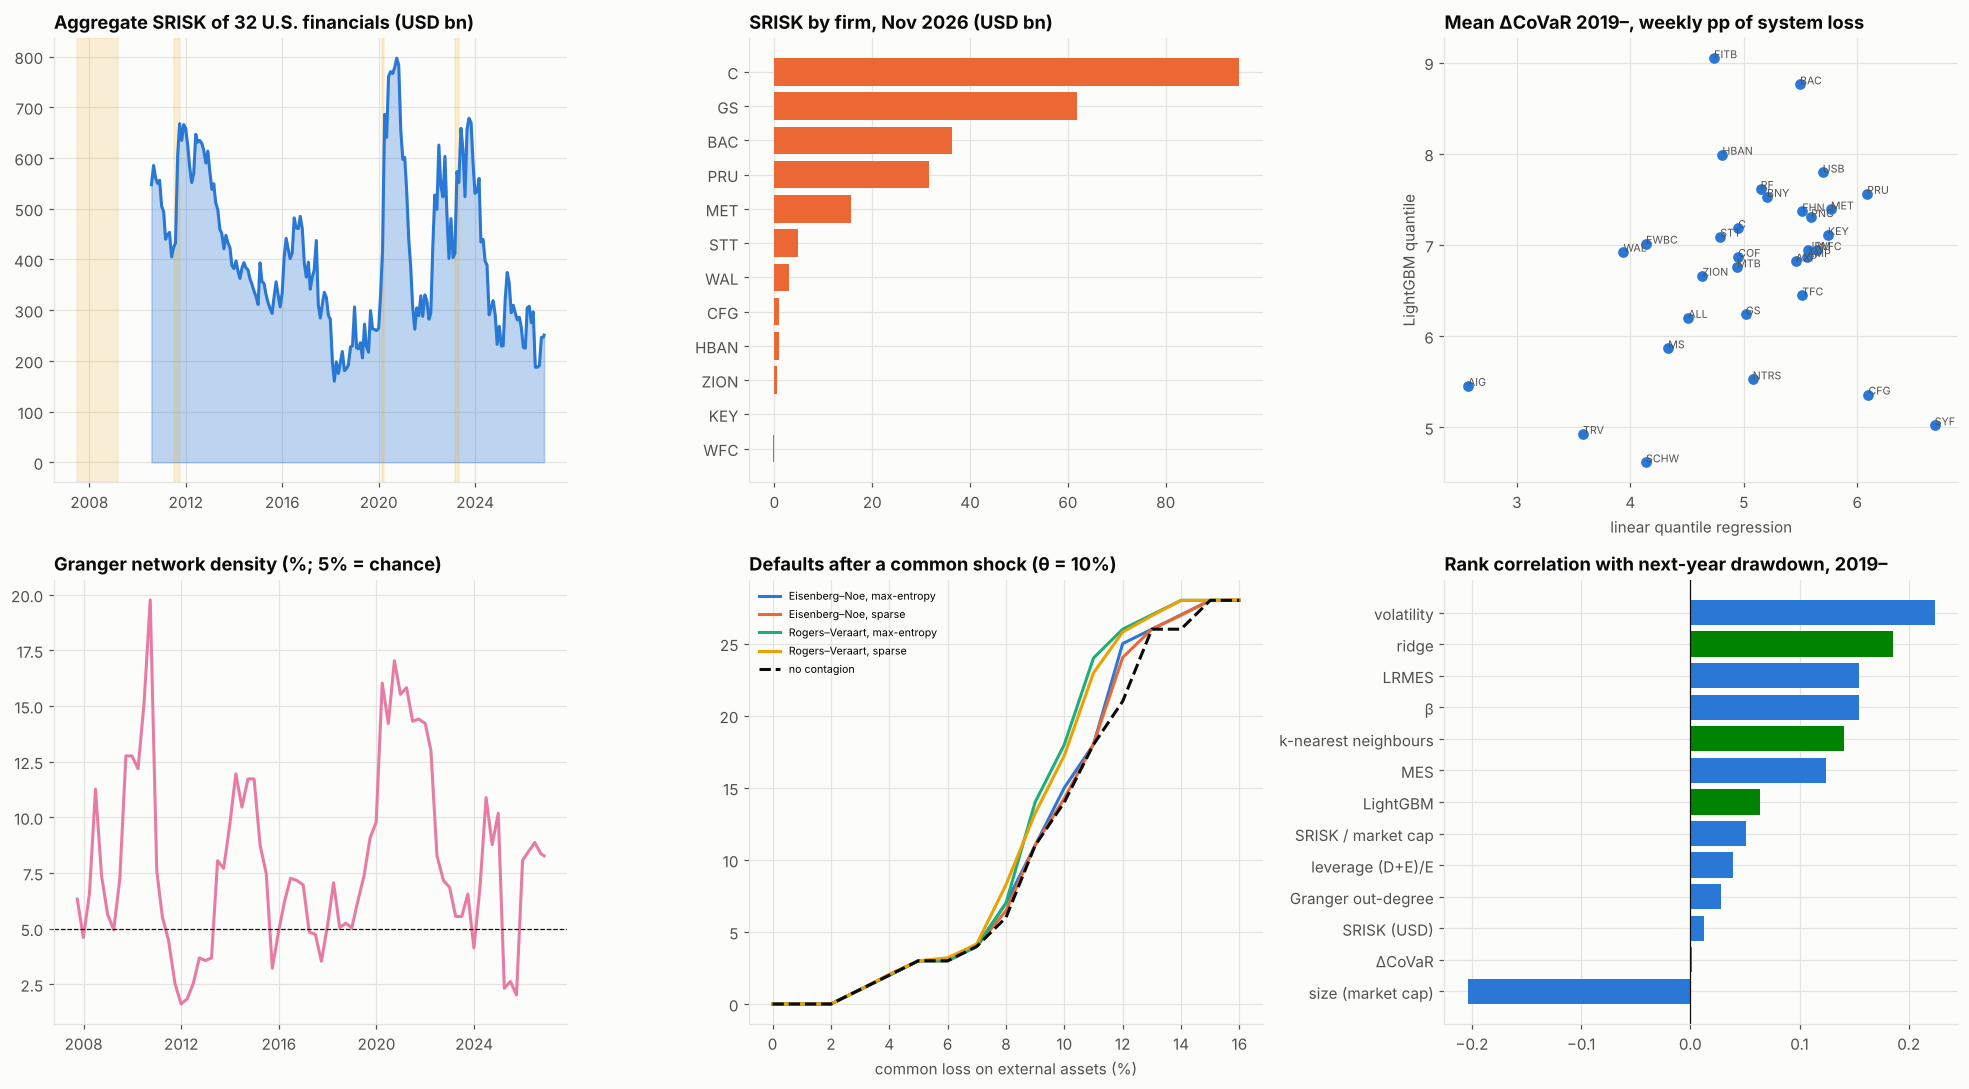

In [15]:
RANK = pd.DataFrame({
    "SRISK, USD bn": now.srisk,
    "share of positive SRISK": (
        now.srisk.clip(lower=0) / now.srisk.clip(lower=0).sum()
    ),
    "LRMES": now.lrmes,
    "MES": now.mes,
    "ΔCoVaR (latest, pp)": DCV.dcovar * 100,
    "Granger out-degree": OUTDEG.iloc[-1],
    "Granger in-degree": INDEG.iloc[-1],
    "loss imposed on others if it fails (RV, sparse), USD bn": PER_FIRM[
        "Rogers–Veraart"
    ]["sparse (mean)"],
})
RANK.insert(0, "type", pd.Series(FIRMS))
corr = RANK.drop(columns=["type", "share of positive SRISK"]).corr(
    method="spearman"
)

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
a = ax[0, 0]
a.fill_between(AGG.index, AGG.values, color=PALETTE[0], alpha=0.3)
a.plot(AGG.index, AGG.values, color=PALETTE[0])
for _, (dm, s0, s1) in EPISODES.items():
    a.axvspan(pd.Timestamp(s0), pd.Timestamp(s1), color=PALETTE[3], alpha=0.15)
a.set_title("Aggregate SRISK of 32 U.S. financials (USD bn)")
a = ax[0, 1]
top = RANK["SRISK, USD bn"].sort_values().tail(12)
a.barh(
    top.index,
    top.values,
    color=[PALETTE[1] if v > 0 else PALETTE[2] for v in top.values],
)
a.set_title(f"SRISK by firm, {M_.date.max():%b %Y} (USD bn)")
a = ax[0, 2]
a.scatter(
    DCV.dcovar_mean_2019_ * 100, DCV.dcovar_gbm_2019_ * 100, color=PALETTE[0]
)
for t_, r_ in DCV.iterrows():
    a.annotate(
        t_,
        (r_.dcovar_mean_2019_ * 100, r_.dcovar_gbm_2019_ * 100),
        fontsize=7,
        color=INK_2,
    )
a.set_xlabel("linear quantile regression")
a.set_ylabel("LightGBM quantile")
a.set_title("Mean ΔCoVaR 2019–, weekly pp of system loss")
a = ax[1, 0]
a.plot(GR.index, GR.values * 100, color=PALETTE[4])
a.axhline(5, color=INK, ls="--", lw=0.8)
a.set_title("Granger network density (%; 5% = chance)")
a = ax[1, 1]
for j_, ((cname, net), v) in enumerate(CS.items()):
    a.plot(
        v.index * 100,
        v["defaults"],
        color=PALETTE[j_],
        label=f"{cname}, {net}",
    )
a.plot(
    SHOCKS * 100,
    CS[("Eisenberg–Noe", "max-entropy")]["defaults, no contagion"],
    color=INK,
    ls="--",
    label="no contagion",
)
a.set_xlabel("common loss on external assets (%)")
a.set_title(f"Defaults after a common shock (θ = {THETA:.0%})")
a.legend(fontsize=7)
a = ax[1, 2]
pp = PRED["mean Spearman"].sort_values()
a.barh(
    pp.index,
    pp.values,
    color=[PALETTE[5] if k in models else PALETTE[0] for k in pp.index],
)
a.axvline(0, color=INK, lw=0.8)
a.set_title("Rank correlation with next-year drawdown, 2019–")
fig.tight_layout()
save_fig(fig, "01_systemic_risk_overview")
plt.show()

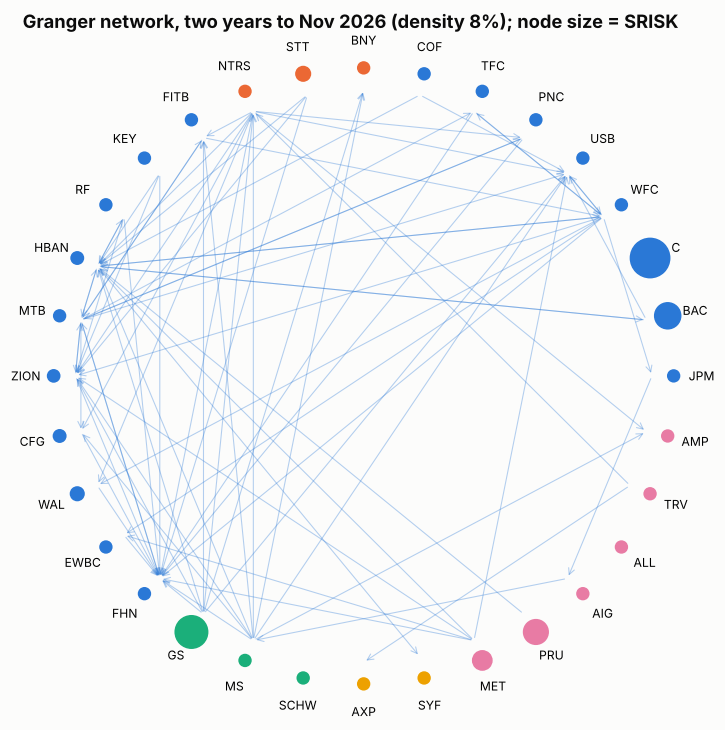

In [16]:
# latest Granger network on a circle; node size = positive SRISK
Adj = NETS[QE[-1]]
ang = np.linspace(0, 2 * np.pi, len(TICKERS), endpoint=False)
xy = np.column_stack([np.cos(ang), np.sin(ang)])
fig, ax_ = plt.subplots(figsize=(8, 8))
for i_ in range(len(TICKERS)):
    for j_ in range(len(TICKERS)):
        if Adj[i_, j_] == 1:
            ax_.annotate(
                "",
                xy=xy[j_] * 0.93,
                xytext=xy[i_] * 0.93,
                arrowprops=dict(
                    arrowstyle="->", color=PALETTE[0], alpha=0.35, lw=0.7
                ),
            )
size = 60 + 600 * now.srisk.clip(lower=0).reindex(TICKERS).fillna(0) / max(
    now.srisk.max(), 1
)
col = [
    PALETTE[
        [
            "bank",
            "custody bank",
            "broker-dealer",
            "card lender",
            "insurer",
        ].index(FIRMS[t])
    ]
    for t in TICKERS
]
ax_.scatter(xy[:, 0], xy[:, 1], s=size, c=col, zorder=3)
for t_, (x_, y_) in zip(TICKERS, xy):
    ax_.annotate(
        t_, (x_ * 1.09, y_ * 1.09), ha="center", va="center", fontsize=8
    )
ax_.set_axis_off()
ax_.set_title(
    f"Granger network, two years to {QE[-1]:%b %Y} (density"
    f" {GR.iloc[-1]:.0%}); node size = SRISK"
)
save_fig(fig, "02_granger_network")
plt.show()

In [17]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Aggregate SRISK (USD bn)",
        "SRISK by firm today (USD bn)",
        "Granger network density",
        "Rank correlation with next-year drawdown, 2019–",
    ),
)
dash.add_trace(
    go.Scatter(
        x=AGG.index,
        y=AGG.values,
        fill="tozeroy",
        line_color=PALETTE[0],
        name="SRISK",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=top.values,
        y=top.index,
        orientation="h",
        marker_color=PALETTE[1],
        name="SRISK by firm",
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(x=GR.index, y=GR.values, line_color=PALETTE[4], name="density"),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=pp.values,
        y=pp.index,
        orientation="h",
        marker_color=PALETTE[5],
        name="Spearman",
    ),
    2,
    2,
)
dash.update_layout(
    height=800,
    width=1400,
    template="simple_white",
    showlegend=False,
    title="Systemic risk of U.S. financial institutions",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

*Prices are re-read daily and balance sheets weekly; the figures below are from the run date and move with markets.*

**The capital shortfall of the system.** Aggregate SRISK of the 32 firms was about USD 550 bn in mid-2010 and 670 bn in the 2011 euro crisis, fell to a low of USD 160 bn in early 2018, jumped to its peak of USD 797 bn in September 2020 and stayed above USD 600 bn through the 2022–2023 rate shock and bank turmoil. Today it is about USD 250 bn. Five firms carry all of it:

| Firm | SRISK, USD bn | Share | Why |
|---|---|---|---|
| Citigroup | 95 | 38% | largest liabilities relative to market value (balance sheet of December 2025, the latest in the SEC's XBRL data) |
| Goldman Sachs | 62 | 25% | highest LRMES (58%) |
| Bank of America | 36 | 15% | size |
| Prudential | 32 | 13% | low book equity |
| MetLife | 16 | 6% | low book equity |

JPMorgan, with a capital *surplus* of USD 176 bn in the crisis scenario, shows that size alone does not make SRISK: a high market value relative to debt does the opposite.

**ΔCoVaR.** Conditioning on the firm's return halves the out-of-time pinball loss of the system's 5% quantile against an unconditional quantile (median 2.7 vs 5.5 × 10⁻³). The gradient-boosted model is no better than the linear one (2.8, better for half the firms) and is worse calibrated: the system falls below its 5% quantile in 7.8% of test weeks against 4.6% for the linear model. The two rank firms differently (rank correlation 0.28). Because the 32 firms move together, ΔCoVaR barely separates them: 2.9 to 6.4 percentage points of weekly system loss.

**Networks.** The Granger network is denser than chance (median density 7.2% against 5%). It was densest in the two years to September 2010, at 20%, and it is at 8.3% today. Contagion through the estimated exposures is small:

- With a maximum-entropy network, no single failure brings down another firm, even when 30% of liabilities are owed inside the network.
- With sparse networks, 3–5% of failures cause another default at θ = 10%, and at most two. At θ = 30% with default costs, 23% do, with up to five.
- In a common shock, the defaults come from thin book equity, not from the network. MetLife and Ameriprise fail first, at a 4% loss on external assets, because their book equity is about 3% of assets. Clearing adds at most a few defaults near the threshold and amplifies equity losses by less than 1% without default costs and by about 4% with them.

**Do the measures find the losers?** The evidence is mixed.

| Rank correlation with the realised loss | β / LRMES | MES | Volatility | Leverage | SRISK / market cap | Size | ΔCoVaR | Granger out-degree |
|---|---|---|---|---|---|---|---|---|
| Global financial crisis (2007–09) | −0.28 | −0.36 | −0.20 | – | – | – | −0.02 | – |
| Downgrade and euro crisis (2011) | 0.26 | 0.23 | 0.38 | 0.52 | 0.53 | −0.05 | 0.07 | −0.13 |
| COVID crash (2020) | 0.26 | 0.29 | 0.20 | 0.30 | 0.37 | −0.25 | −0.05 | −0.17 |
| Regional-bank turmoil (2023) | 0.27 | 0.14 | 0.40 | 0.01 | 0.05 | −0.65 | −0.02 | −0.26 |
| Next-year drawdown, 2019–2025 (mean per quarter) | 0.16 | 0.13 | 0.22 | 0.04 | 0.05 | −0.20 | 0.00 | 0.03 |

- **Leverage-based measures caught the crises driven by capital (2011, 2020), but not the one driven by deposits (2023).** In March 2023 the losers were small regional banks with flighty deposits, so size ranks them best (−0.65), and SRISK, built on market leverage, misses them.
- **Simple volatility is the most reliable predictor of next-year drawdowns** (0.22, positive in 85% of quarters). Ridge on all measures reaches 0.19, and k-nearest neighbours 0.14. LightGBM overfits the 34 training quarters (0.06).
- **ΔCoVaR and Granger out-degree do not rank losers at all.** They measure what a firm does to others, not what happens to it, which is the right design for a surcharge but means they cannot be validated on the firm's own losses.
- **The global financial crisis shows survivorship bias.** The firms that failed or were absorbed in 2008 (Lehman, Bear Stearns, Merrill Lynch, Wachovia, Washington Mutual, Countrywide) are not in Yahoo's data, and among the survivors the high-beta broker-dealers and custodians of 2007 (Goldman Sachs, Morgan Stanley, Schwab, State Street) lost less than lower-beta lenders hit by credit losses (AIG, Fifth Third, Huntington, Zions).

**Limitations.**
- **Book liabilities and survivors.** SRISK uses total book liabilities, including insurers' long-dated policyholder liabilities, which are not runnable; there is no SRISK before 2010; and the sample contains only firms listed today.
- **The exposure network is assumed, not observed.** θ, the sparsity and the default costs are choices; real bilateral exposures (derivatives, repo, securities holdings) are confidential, and contagion through fire sales and funding runs is not modelled.

In [18]:
AGG.rename("aggregate SRISK, USD bn").to_csv(
    OUT_DIR / "aggregate_srisk_monthly.csv"
)
RANK.to_csv(OUT_DIR / "systemic_importance_latest.csv")
FIT.to_csv(OUT_DIR / "covar_pinball_out_of_time.csv")
GR.rename("granger density").to_csv(OUT_DIR / "granger_density_quarterly.csv")
CONTAGION.to_csv(OUT_DIR / "contagion_idiosyncratic_failures.csv", index=False)
pd.concat({f"{a}, {b}": v for (a, b), v in CS.items()}, axis=1).to_csv(
    OUT_DIR / "contagion_common_shock.csv"
)
EPI.to_csv(OUT_DIR / "episode_rank_correlations.csv")
PRED.to_csv(OUT_DIR / "drawdown_prediction_out_of_time.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_systemic_risk_overview.png, 02_granger_network.png, aggregate_srisk_monthly.csv, contagion_common_shock.csv, contagion_idiosyncratic_failures.csv, covar_pinball_out_of_time.csv, dashboard.html, dashboard.png, drawdown_prediction_out_of_time.csv, episode_rank_correlations.csv, granger_density_quarterly.csv, systemic_importance_latest.csv


## References

- Acharya, V. V., Pedersen, L. H., Philippon, T., & Richardson, M. (2017). Measuring systemic risk. *Review of Financial Studies*, 30(1), 2–47. https://doi.org/10.1093/rfs/hhw088
- Acharya, V., Engle, R., & Richardson, M. (2012). Capital shortfall: A new approach to ranking and regulating systemic risks. *American Economic Review*, 102(3), 59–64.
- Adrian, T., & Brunnermeier, M. K. (2016). CoVaR. *American Economic Review*, 106(7), 1705–1741. https://doi.org/10.1257/aer.20120555
- Billio, M., Getmansky, M., Lo, A. W., & Pelizzon, L. (2012). Econometric measures of connectedness and systemic risk in the finance and insurance sectors. *Journal of Financial Economics*, 104(3), 535–559.
- Brownlees, C., & Engle, R. F. (2017). SRISK: A conditional capital shortfall measure of systemic risk. *Review of Financial Studies*, 30(1), 48–79. https://doi.org/10.1093/rfs/hhw060
- Eisenberg, L., & Noe, T. H. (2001). Systemic risk in financial systems. *Management Science*, 47(2), 236–249.
- Glasserman, P., & Young, H. P. (2015). How likely is contagion in financial networks? *Journal of Banking & Finance*, 50, 383–399.
- Koenker, R., & Bassett, G. (1978). Regression quantiles. *Econometrica*, 46(1), 33–50.
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30*.
- Mistrulli, P. E. (2011). Assessing financial contagion in the interbank market: Maximum entropy versus observed interbank lending patterns. *Journal of Banking & Finance*, 35(5), 1114–1127.
- Rogers, L. C. G., & Veraart, L. A. M. (2013). Failure and rescue in an interbank network. *Management Science*, 59(4), 882–898.
- Upper, C. (2011). Simulation methods to assess the danger of contagion in interbank markets. *Journal of Financial Stability*, 7(3), 111–125.
- NYU Stern Volatility Lab. *SRISK methodology* (LRMES = 1 − exp(log(1 − d) · β), d = 40%, k = 8%). https://vlab.stern.nyu.edu/srisk
- U.S. Securities and Exchange Commission. *EDGAR XBRL company facts API*. https://www.sec.gov/edgar/sec-api-documentation